# 01 · Exploración de datos originales

**Proyecto:** Text-to-SQL con Schema Linking — Entrega 1 (Data Engineering).

Objetivo de este notebook:

1. Inventariar los archivos disponibles en `raw/` (Spider 1.0, BIRD-SQL y Catastro).
2. Cargar cada fuente e inspeccionar su estructura real (campos, formatos, metadatos de esquemas).
3. Calcular estadísticas iniciales y documentar los problemas detectados.

> Los datos originales **no se modifican**. Toda la lógica de carga vive en `src/data_loader.py` y `src/schema_parser.py`;
> este notebook solo la invoca.


In [7]:
# Configuración común: localizar la raíz del proyecto y habilitar `src/`
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

from src import config
config.ensure_directories()
print("Raíz del proyecto:", ROOT.name)

Raíz del proyecto: proyecto_jarm


## 1. Inventario de archivos en `raw/`

In [8]:
from src.data_loader import inventory_raw_files

inventory = inventory_raw_files()
inventory

,source,path,format,size_mb,n_records
0,SPIDER,raw/spider_data/.DS_Store,no-extension,0.01,NaN
1,SPIDER,raw/spider_data/database,directory,NaN,166.0
2,SPIDER,raw/spider_data/dev.json,json,3.63,1034.0
3,SPIDER,raw/spider_data/dev_gold.sql,sql (líneas),0.12,1034.0
4,SPIDER,raw/spider_data/README.txt,txt,0.01,NaN
5,SPIDER,raw/spider_data/tables.json,json,0.81,166.0
6,SPIDER,raw/spider_data/test.json,json,7.80,2147.0
7,SPIDER,raw/spider_data/test_database,directory,NaN,206.0
8,SPIDER,raw/spider_data/test_gold.sql,sql (líneas),0.27,2147.0
9,SPIDER,raw/spider_data/test_tables.json,json,0.76,206.0


Observaciones del inventario:

* Los datos están en `raw/`; `src/config.py` apunta a ella.
* Spider incluye los archivos `train_others.json` (1.659) y `test.json` (2.147). **se excluyen del dataset maestro**  solo se reportan aquí. (Se incluyen solo train de 7.000 ejemplos y 1.034 ejemplos de validacion)
* BIRD solo dispone de los JSON de preguntas y de metadatos de esquema (`*_tables.json`); no están las bases `.sqlite` (se requieren para la etapa de validación).
* Catastro aporta un Excel con 80 pares regla–SQL y un `pg_dump` en texto plano (26 MB) con el DDL completo del esquema `unidad_intervencion_18`.


## 2. Spider 1.0

### 2.1 Estructura de los ejemplos

In [9]:
from src.data_loader import load_json

spider_train = load_json(config.SPIDER_FILES["train"])
print("Campos de cada ejemplo:", list(spider_train[0].keys()))
print("\nEjemplo:")
print(json.dumps({k: v for k, v in spider_train[0].items() if k not in ("sql", "query_toks", "query_toks_no_value", "question_toks")}, indent=2, ensure_ascii=False))
print("\nClaves del SQL pre-parseado de Spider (no se usa; se hará con SQLGlot):", list(spider_train[0]["sql"].keys()))

Campos de cada ejemplo: ['db_id', 'query', 'query_toks', 'query_toks_no_value', 'question', 'question_toks', 'sql']

Ejemplo:
{
  "db_id": "department_management",
  "query": "SELECT count(*) FROM head WHERE age  >  56",
  "question": "How many heads of the departments are older than 56 ?"
}

Claves del SQL pre-parseado de Spider (no se usa; se hará con SQLGlot): ['from', 'select', 'where', 'groupBy', 'having', 'orderBy', 'limit', 'intersect', 'union', 'except']


In [10]:
from src.data_loader import load_spider_raw

spider_all = load_spider_raw(include_extra=True)
spider_all.groupby("source_split").agg(n_examples=("question", "size"), n_dbs=("db_id", "nunique"))

2026-11-06 11:09:29,209 | INFO | src.data_loader | Spider train: 7000 ejemplos, 140 bases
2026-11-06 11:09:29,244 | INFO | src.data_loader | Spider dev: 1034 ejemplos, 20 bases
2026-11-06 11:09:29,288 | INFO | src.data_loader | Spider train_others: 1659 ejemplos, 6 bases
2026-11-06 11:09:29,330 | INFO | src.data_loader | Spider test: 2147 ejemplos, 40 bases


,n_examples,n_dbs
source_split,,
dev,1034,20
test,2147,40
train,7000,140
train_others,1659,6


In [11]:
spider = spider_all[spider_all.source_split.isin(["train", "dev"])]
train_dbs, dev_dbs = set(spider[spider.source_split == "train"].db_id), set(spider[spider.source_split == "dev"].db_id)
print(f"Spider oficial: {len(spider)} ejemplos | bases train={len(train_dbs)} dev={len(dev_dbs)} union={len(train_dbs | dev_dbs)} intersección={len(train_dbs & dev_dbs)}")

Spider oficial: 8034 ejemplos | bases train=140 dev=20 union=160 intersección=0


### 2.2 Metadatos de esquema (`tables.json`)

In [12]:
tables = load_json(config.SPIDER_FILES["tables"])
entry = next(t for t in tables if t["db_id"] == "concert_singer")
print("Campos:", list(entry.keys()))
print("db_id:", entry["db_id"])
print("table_names_original:", entry["table_names_original"])
print("table_names (normalizados):", entry["table_names"])
print("column_names_original[:8]:", entry["column_names_original"][:8])
print("column_types[:8]:", entry["column_types"][:8])
print("primary_keys:", entry["primary_keys"], "| foreign_keys:", entry["foreign_keys"])
print(f"\nEsquemas en tables.json: {len(tables)} | bases de train+dev sin esquema: {sorted((train_dbs | dev_dbs) - {t['db_id'] for t in tables})}")

Campos: ['column_names', 'column_names_original', 'column_types', 'db_id', 'foreign_keys', 'primary_keys', 'table_names', 'table_names_original']
db_id: concert_singer
table_names_original: ['stadium', 'singer', 'concert', 'singer_in_concert']
table_names (normalizados): ['stadium', 'singer', 'concert', 'singer in concert']
column_names_original[:8]: [[-1, '*'], [0, 'Stadium_ID'], [0, 'Location'], [0, 'Name'], [0, 'Capacity'], [0, 'Highest'], [0, 'Lowest'], [0, 'Average']]
column_types[:8]: ['text', 'number', 'text', 'text', 'number', 'number', 'number', 'number']
primary_keys: [1, 8, 15, 20] | foreign_keys: [[18, 1], [21, 8], [20, 15]]

Esquemas en tables.json: 166 | bases de train+dev sin esquema: []


Interpretación de los índices (válida para Spider y BIRD):

* `column_names_original[i] = [table_index, column_name]`. El índice de tabla **-1** corresponde al comodín `*` y **no** es una columna real.
* `primary_keys` y `foreign_keys` referencian índices de `column_names_original`. En BIRD las claves primarias compuestas aparecen como listas anidadas (p. ej. `[19, 20]`).


## 3. BIRD-SQL

### 3.1 Estructura de los ejemplos

In [13]:
bird_train = load_json(config.BIRD_FILES["train"])
bird_dev = load_json(config.BIRD_FILES["dev"])
print("Campos train:", list(bird_train[0].keys()))
print("Campos dev  :", list(bird_dev[0].keys()))
print("\nEjemplo dev:")
print(json.dumps(bird_dev[0], indent=2, ensure_ascii=False))

Campos train: ['db_id', 'question', 'evidence', 'SQL']
Campos dev  : ['question_id', 'db_id', 'question', 'evidence', 'SQL', 'difficulty']

Ejemplo dev:
{
  "question_id": 0,
  "db_id": "california_schools",
  "question": "What is the highest eligible free rate for K-12 students in the schools in Alameda County?",
  "evidence": "Eligible free rate for K-12 = `Free Meal Count (K-12)` / `Enrollment (K-12)`",
  "SQL": "SELECT `Free Meal Count (K-12)` / `Enrollment (K-12)` FROM frpm WHERE `County Name` = 'Alameda' ORDER BY (CAST(`Free Meal Count (K-12)` AS REAL) / `Enrollment (K-12)`) DESC LIMIT 1",
  "difficulty": "simple"
}


In [14]:
from src.data_loader import load_bird_raw

bird = load_bird_raw()
bird["evidence_vacia"] = bird.evidence.str.strip() == ""
bird.groupby("source_split").agg(n_examples=("question", "size"), n_dbs=("db_id", "nunique"), evidencias_vacias=("evidence_vacia", "sum"))

2026-11-06 11:10:08,071 | INFO | src.data_loader | BIRD train: 9428 ejemplos, 69 bases, 645 evidencias vacías
2026-11-06 11:10:08,080 | INFO | src.data_loader | BIRD dev: 1534 ejemplos, 11 bases, 148 evidencias vacías


,n_examples,n_dbs,evidencias_vacias
source_split,,,
dev,1534,11,148
train,9428,69,645


In [15]:
# Sugerencia: puede serutil incluir las de dificultad alta al conjunto de entrenamiento,
# ya que son pocas y pueden ayudar a mejorar la generalización del modelo,
# proyectandose como apoyo para las catastrales dificiles.
bird.loc[bird["difficulty"]==  'challenging']

,source_split,source_file,source_index,db_id,question,sql_gold,evidence,difficulty,evidence_vacia
9456,dev,raw/bird_data/dev.json,28,california_schools,"Consider the average difference between K-12 enrollment and 15-17 enrollment of schools that are locally funded, lis...","SELECT T2.School, T2.DOC FROM frpm AS T1 INNER JOIN schools AS T2 ON T1.CDSCode = T2.CDSCode WHERE T2.FundingType = ...",Difference between K-12 enrollment and 15-17 enrollment can be computed by `Enrollment (K-12)` - `Enrollment (Ages 5...,challenging,False
9464,dev,raw/bird_data/dev.json,36,california_schools,Under whose administration is the school with the highest number of students scoring 1500 or more on the SAT? Indica...,"SELECT T2.AdmFName1, T2.AdmLName1, T2.AdmFName2, T2.AdmLName2, T2.AdmFName3, T2.AdmLName3 FROM satscores AS T1 INNER...","full name means first name, last name; There are at most 3 administrators for each school; SAT Scores are greater or...",challenging,False
9490,dev,raw/bird_data/dev.json,62,california_schools,What is the total number of non-chartered schools in the county of Los Angeles with a percent (%) of eligible free m...,SELECT COUNT(T2.School) FROM frpm AS T1 INNER JOIN schools AS T2 ON T1.CDSCode = T2.CDSCode WHERE T2.County = 'Los A...,non-chartered schools refer to schools whose Charter = 0; K-12 means grades 1 through 12; percent of eligible free r...,challenging,False
9511,dev,raw/bird_data/dev.json,83,california_schools,"Of the schools that offers a magnet program serving a grade span of Kindergarten to 8th grade, how many offers Multi...","SELECT T2.City, COUNT(T2.CDSCode) FROM frpm AS T1 INNER JOIN schools AS T2 ON T1.CDSCode = T2.CDSCode WHERE T2.Magne...",Kindergarten to 8th grade refers to K-8; 'Offers a magnet program' means Magnet = 1; Multiple Provision Types refers...,challenging,False
9515,dev,raw/bird_data/dev.json,87,california_schools,"What are the valid e-mail addresses of the administrator of the school located in the San Bernardino county, City of...","SELECT T2.AdmEmail1, T2.AdmEmail2 FROM frpm AS T1 INNER JOIN schools AS T2 ON T1.CDSCode = T2.CDSCode WHERE T2.Count...",Intermediate/Middle Schools refers to SOC = 62; Unified School refers to DOC = 54; years between 2009 and 2010 can r...,challenging,False
...,...,...,...,...,...,...,...,...,...
10892,dev,raw/bird_data/dev.json,1464,student_club,Write the full names of students who received funds on the date of 9/9/2019 and include the amount received.,"SELECT DISTINCT T3.first_name, T3.last_name, T4.amount FROM event AS T1 INNER JOIN attendance AS T2 ON T1.event_id =...","full name refers to first_name, last_name, amount of funds received refers to amount, received funds on date refers ...",challenging,False
10904,dev,raw/bird_data/dev.json,1476,debit_card_specializing,What was the difference in gas consumption between CZK-paying customers and EUR-paying customers in 2012?,"SELECT SUM(IIF(T1.Currency = 'CZK', T2.Consumption, 0)) - SUM(IIF(T1.Currency = 'EUR', T2.Consumption, 0)) FROM cust...",Year 2012 can be presented as Between 201201 And 201212; The first 4 strings of the Date values in the yearmonth tab...,challenging,False
10909,dev,raw/bird_data/dev.json,1481,debit_card_specializing,What is the difference in the annual average consumption of the customers with the least amount of consumption paid ...,"SELECT CAST(SUM(IIF(T1.Segment = 'SME', T2.Consumption, 0)) AS REAL) / COUNT(T1.CustomerID) - CAST(SUM(IIF(T1.Segmen...",annual average consumption of customer with the lowest consumption in each segment = total consumption per year / th...,challenging,False
10910,dev,raw/bird_data/dev.json,1482,debit_card_specializing,"Which of the three segments—SME, LAM and KAM—has the biggest and lowest percentage increases in consumption paid in ...","SELECT CAST((SUM(IIF(T1.Segment = 'SME' AND T2.Date LIKE '2013%', T2.Consumption, 0)) - SUM(IIF(T1.Segment = 'SME' A...",Increase or Decrease = consumption for 2013 - consumption for 2012; Percentage of Increa

In [16]:
print("Dificultad (solo dev):", bird[bird.source_split == "dev"].difficulty.value_counts().to_dict())
bird_train_dbs = set(bird[bird.source_split == "train"].db_id); bird_dev_dbs = set(bird[bird.source_split == "dev"].db_id)
print("Intersección de bases train/dev:", bird_train_dbs & bird_dev_dbs)
print("\nEjemplos por base (train, top 10):")
bird[bird.source_split == "train"].db_id.value_counts().head(10)

Dificultad (solo dev): {'simple': 925, 'moderate': 464, 'challenging': 145}
Intersección de bases train/dev: set()

Ejemplos por base (train, top 10):


db_id
works_cycles              474
public_review_platform    381
retail_world              373
movie_3                   325
mondial_geo               293
soccer_2016               258
retails                   245
simpson_episodes          210
hockey                    207
talkingdata               206
Name: count, dtype: int64

### 3.2 Metadatos de esquema (`train_tables.json`, `dev_tables.json`)

In [17]:
bird_tables = load_json(config.BIRD_FILES["train_tables"]) + load_json(config.BIRD_FILES["dev_tables"])
e = next(t for t in bird_tables if t["db_id"] == "debit_card_specializing")
print("Campos:", list(e.keys()))
print("table_names_original:", e["table_names_original"])
print("column_names_original[:6]:", e["column_names_original"][:6])
print("column_types[:6]:", e["column_types"][:6])
print("primary_keys (nótese la PK compuesta):", e["primary_keys"])
print("foreign_keys:", e["foreign_keys"])
print(f"\nEsquemas BIRD: {len(bird_tables)} | bases sin esquema: {sorted((bird_train_dbs | bird_dev_dbs) - {t['db_id'] for t in bird_tables})}")

Campos: ['db_id', 'table_names_original', 'table_names', 'column_names_original', 'column_names', 'column_types', 'primary_keys', 'foreign_keys']
table_names_original: ['customers', 'gasstations', 'products', 'transactions_1k', 'yearmonth']
column_names_original[:6]: [[-1, '*'], [0, 'CustomerID'], [0, 'Segment'], [0, 'Currency'], [1, 'GasStationID'], [1, 'ChainID']]
column_types[:6]: ['text', 'integer', 'text', 'text', 'integer', 'integer']
primary_keys (nótese la PK compuesta): [1, 4, 8, 10, [19, 20]]
foreign_keys: [[19, 1]]

Esquemas BIRD: 80 | bases sin esquema: []


## 4. Catastro

### 4.1 Excel de reglas–SQL

In [18]:
raw_xlsx = pd.read_excel(config.CATASTRO_FILES["questions"])
print("Hoja(s):", pd.ExcelFile(config.CATASTRO_FILES["questions"]).sheet_names)
print("Columnas reales:", list(raw_xlsx.columns), "| filas:", len(raw_xlsx))
print("Nulos por columna:", raw_xlsx.isna().sum().to_dict())
raw_xlsx.head(3)

Hoja(s): ['limpio']
Columnas reales: ['N°', 'Regla', 'SQL (unidad_intervencion_18)'] | filas: 80
Nulos por columna: {'N°': 0, 'Regla': 0, 'SQL (unidad_intervencion_18)': 0}


,N°,Regla,SQL (unidad_intervencion_18)
0,1,Predios de condición NPH que en los campos 22 a 30 del número predial nacional no terminan como 000000000,"WITH tb1 AS (\n SELECT\n ip.t_id,\n ip.numero_predial,\n ic.ilicode AS condicionpredio,\n ..."
1,2,Predios de condición Bien de uso publico que en los campos 22 a 30 del número predial nacional no terminan como 3000...,"WITH tb1 AS (\n SELECT\n ip.t_id,\n ip.numero_predial,\n ic.ilicode AS condicionpredio,\n ..."
2,3,Predios de condición Via que en la posición 22 del numero predial no tienen 4 o que los campos 22 a 30 del número pr...,"WITH tb1 AS (\n SELECT\n ip.t_id,\n ip.numero_predial,\n ic.ilicode AS condicionpredio,\n ..."


In [19]:
from src.data_loader import load_catastro_raw

catastro = load_catastro_raw()
print("Columnas homologadas:", list(catastro.columns))
print("Duplicados (pregunta):", catastro.question.duplicated().sum(), "| duplicados (SQL):", catastro.sql_gold.duplicated().sum())
print("\nEjemplo (regla 41):")
print(catastro.question[40]); print(catastro.sql_gold[40])

2026-11-06 11:12:41,730 | INFO | src.data_loader | Catastro: 80 pares (columnas detectadas: pregunta='Regla', sql='SQL (unidad_intervencion_18)')


Columnas homologadas: ['source_split', 'source_file', 'source_index', 'source_row_number', 'db_id', 'question', 'sql_gold']
Duplicados (pregunta): 0 | duplicados (SQL): 0

Ejemplo (regla 41):
Predios de tipo presunto baldio con derecho de tipo ocupación e interesado LA NACION O ANT
SELECT
    lp.t_id,
    lp.numero_predial,
    lp.condicion_predio,
    ld2.ilicode,
    lp.matricula_inmobiliaria,
    cu.ilicode,
    LI.NOMBRE
FROM unidad_intervencion_18.lc_predio lp
LEFT JOIN unidad_intervencion_18.lc_derecho ld ON lp.t_id = ld.unidad
LEFT JOIN unidad_intervencion_18.lc_derechotipo ld2 ON ld2.t_id = ld.tipo
LEFT JOIN unidad_intervencion_18.col_unidadadministrativabasicatipo cu ON cu.t_id = lp.tipo
LEFT JOIN unidad_intervencion_18.lc_interesado li ON li.t_id = ld.interesado_lc_interesado
WHERE cu.ilicode LIKE '%Baldio%'
  AND ld2.ilicode LIKE 'Ocupacion%'
  AND (li.nombre LIKE ('%LA NACIO%') OR li.nombre LIKE ('%ANT%'));


Las "preguntas" catastrales son **reglas de validación** redactadas en español (no preguntas interrogativas) y sus SQL usan
PostgreSQL (CTE, `UNION ALL`, `COUNT(*) FILTER (WHERE ...)`, `LEFT JOIN` múltiples, identificadores con mayúsculas como `LI.NOMBRE`).
Se conservan tal cual: no se traducen ni se adaptan a SQLite.

### 4.2 Esquema real: `pg_dump` de la base `unidad_intervencion_18`

In [20]:
from src.schema_parser import parse_pg_dump_schema

cat_schema = parse_pg_dump_schema(config.CATASTRO_FILES["dump_sql"], config.CATASTRO_PG_SCHEMA, config.CATASTRO_DB_ID)
print(f"Tablas: {cat_schema['n_tables']} | Columnas: {cat_schema['n_columns']} | PK: {len(cat_schema['primary_keys'])} | FK: {len(cat_schema['foreign_keys'])} | Vistas (no candidatas): {cat_schema['views']}")
print("Incidencias de parseo:", cat_schema["issues"])
pd.DataFrame(cat_schema["columns"])[lambda d: d.table_name == "lc_predio"][["table_name", "name_original", "column_type", "is_primary_key", "description"]].head(12)

2026-11-06 11:13:20,853 | INFO | src.schema_parser | Catastro: 232 tablas, 1821 columnas, 228 PK, 319 FK, 697 comentarios, 1 vistas (no candidatas)
Tablas: 232 | Columnas: 1821 | PK: 228 | FK: 319 | Vistas (no candidatas): ['vw_validadores_sinic']
Incidencias de parseo: []


,table_name,name_original,column_type,is_primary_key,description
1355,lc_predio,t_id,bigint,True,NaN
1356,lc_predio,t_ili_tid,uuid,False,NaN
1357,lc_predio,departamento,varchar(2),False,Corresponde al código del departamento al cual pertenece el predio. Es asignado por DIVIPOLA y tiene 2 dígitos.
1358,lc_predio,municipio,varchar(3),False,Corresponde al código del municipio al cual pertenece el predio. Es asignado por DIVIPOLA y tiene 3 dígitos.
1359,lc_predio,id_operacion,varchar(30),False,Identificador único temporal de cada predio que se asigna en el desarrollo del levantamiento catastral.
1360,lc_predio,tiene_fmi,boolean,False,Indica si el predio tiene matricula inmobiliaria.
1361,lc_predio,codigo_orip,varchar(3),False,Circulo registral
1362,lc_predio,matricula_inmobiliaria,varchar(80),False,Matricula inmobiliaria
1363,lc_predio,numero_predial,varchar(30),False,"Nuevo Código numérico de treinta (30) dígitos, que se le asigna a cada predio y busca localizarlo inequívocamente en..."
1364,lc_predio,numero_predial_anterior,varchar(20),False,"Anterior código númerico de veinte (20) digitos, que se le asigna a cada predio y busca localizarlo inequívocamente ..."


In [21]:
import re
refs = pd.Series([t for s in catastro.sql_gold for t in re.findall(r"unidad_intervencion_18\.(\w+)", s)]).value_counts()
schema_tables = {t["name_original"] for t in cat_schema["tables"]}
print("Tablas distintas referenciadas por los 80 SQL:", len(refs), "| referenciadas pero inexistentes en el dump:", sorted(set(refs.index) - schema_tables))
refs.head(15)

Tablas distintas referenciadas por los 80 SQL: 35 | referenciadas pero inexistentes en el dump: []


lc_predio                                         60
lc_condicionprediotipo                            22
lc_derecho                                        17
lc_unidadconstruccion                             15
lc_interesado                                     13
lc_caracteristicasunidadconstruccion              13
lc_estructuranovedadnumeropredial                 12
lc_estructuranovedadnumeropredial_tipo_novedad    10
col_uebaunit                                       9
lc_unidadconstrucciontipo                          9
lc_derechotipo                                     8
lc_interesadotipo                                  8
lc_usouconstipo                                    8
col_unidadadministrativabasicatipo                 7
lc_fuenteadministrativa                            7
Name: count, dtype: int64

## 5. Estadísticas iniciales

In [22]:
frames = [spider.assign(source="SPIDER"), bird.assign(source="BIRD"), catastro.assign(source="CATASTRO")]
basic = pd.concat([f[["source", "source_split", "question", "sql_gold"]] for f in frames], ignore_index=True)
basic["question_chars"] = basic.question.str.len(); basic["question_words"] = basic.question.str.split().str.len()
basic["sql_chars"] = basic.sql_gold.str.len()
basic.groupby(["source", "source_split"]).agg(n=("question", "size"), q_words_mean=("question_words", "mean"), q_words_max=("question_words", "max"), sql_chars_mean=("sql_chars", "mean"), sql_chars_max=("sql_chars", "max")).round(1)

n  q_words_mean  q_words_max  sql_chars_mean  sql_chars_max
source   source_split                                                                
BIRD     dev           1534          14.6           50           161.5           1446
         train         9428          14.1           59           170.1            804
CATASTRO catastro        80          17.3           40           556.5           1259
SPIDER   dev           1034          12.4           28           106.7            422
         train         7000          12.7           39           109.6            577

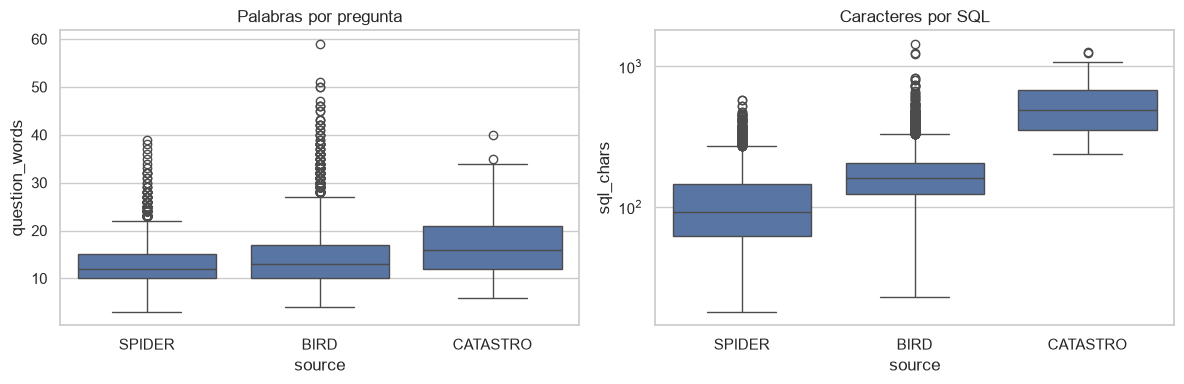

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=basic, x="source", y="question_words", ax=axes[0]); axes[0].set_title("Palabras por pregunta")
sns.boxplot(data=basic, x="source", y="sql_chars", ax=axes[1]); axes[1].set_title("Caracteres por SQL"); axes[1].set_yscale("log")
plt.tight_layout(); plt.show()

## 6. Diagnóstico

| Aspecto | Hallazgo |
|---|---|
| Spider | 7.000 train (140 bases) + 1.034 dev (20 bases) = 8.034, 160 bases; coincide con la propuesta. `train_others` y `test` quedan fuera del alcance. |
| BIRD | 9.428 train (69 bases) + 1.534 dev (11 bases) = 10.962, 80 bases; coincide. 793 evidencias vacías que se conservan. No existen particiones precomputadas: se reconstruyen por `db_id` en el notebook 02. |
| Catastro | 80 reglas–SQL en español (PostgreSQL). Esquema completo disponible desde el `pg_dump`: 232 tablas, 1.821 columnas, 228 PK, 319 FK y 697 comentarios descriptivos. Uso exclusivo para evaluación de transferencia. |
| Esquemas | Índice de tabla -1 = `*`; PK compuestas en BIRD como listas anidadas. |
| Limitaciones | Bases `.sqlite` de BIRD ausentes (no necesarias ahora). La metadata de algunas bases BIRD (`retail_world`, `shooting`) no cubre todas las tablas/columnas usadas por su SQL gold; se cuantifica en el notebook 03. |
